<a href="https://colab.research.google.com/github/JanetIheke993/Healthcare_Records_Analysis/blob/main/DataVisualization_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
np.array([True, 1, 2]) + np.array([3, 4, False])

array([4, 5, 2])

/tmp/ipykernel_2531/310868809.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2531/310868809.py:115: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


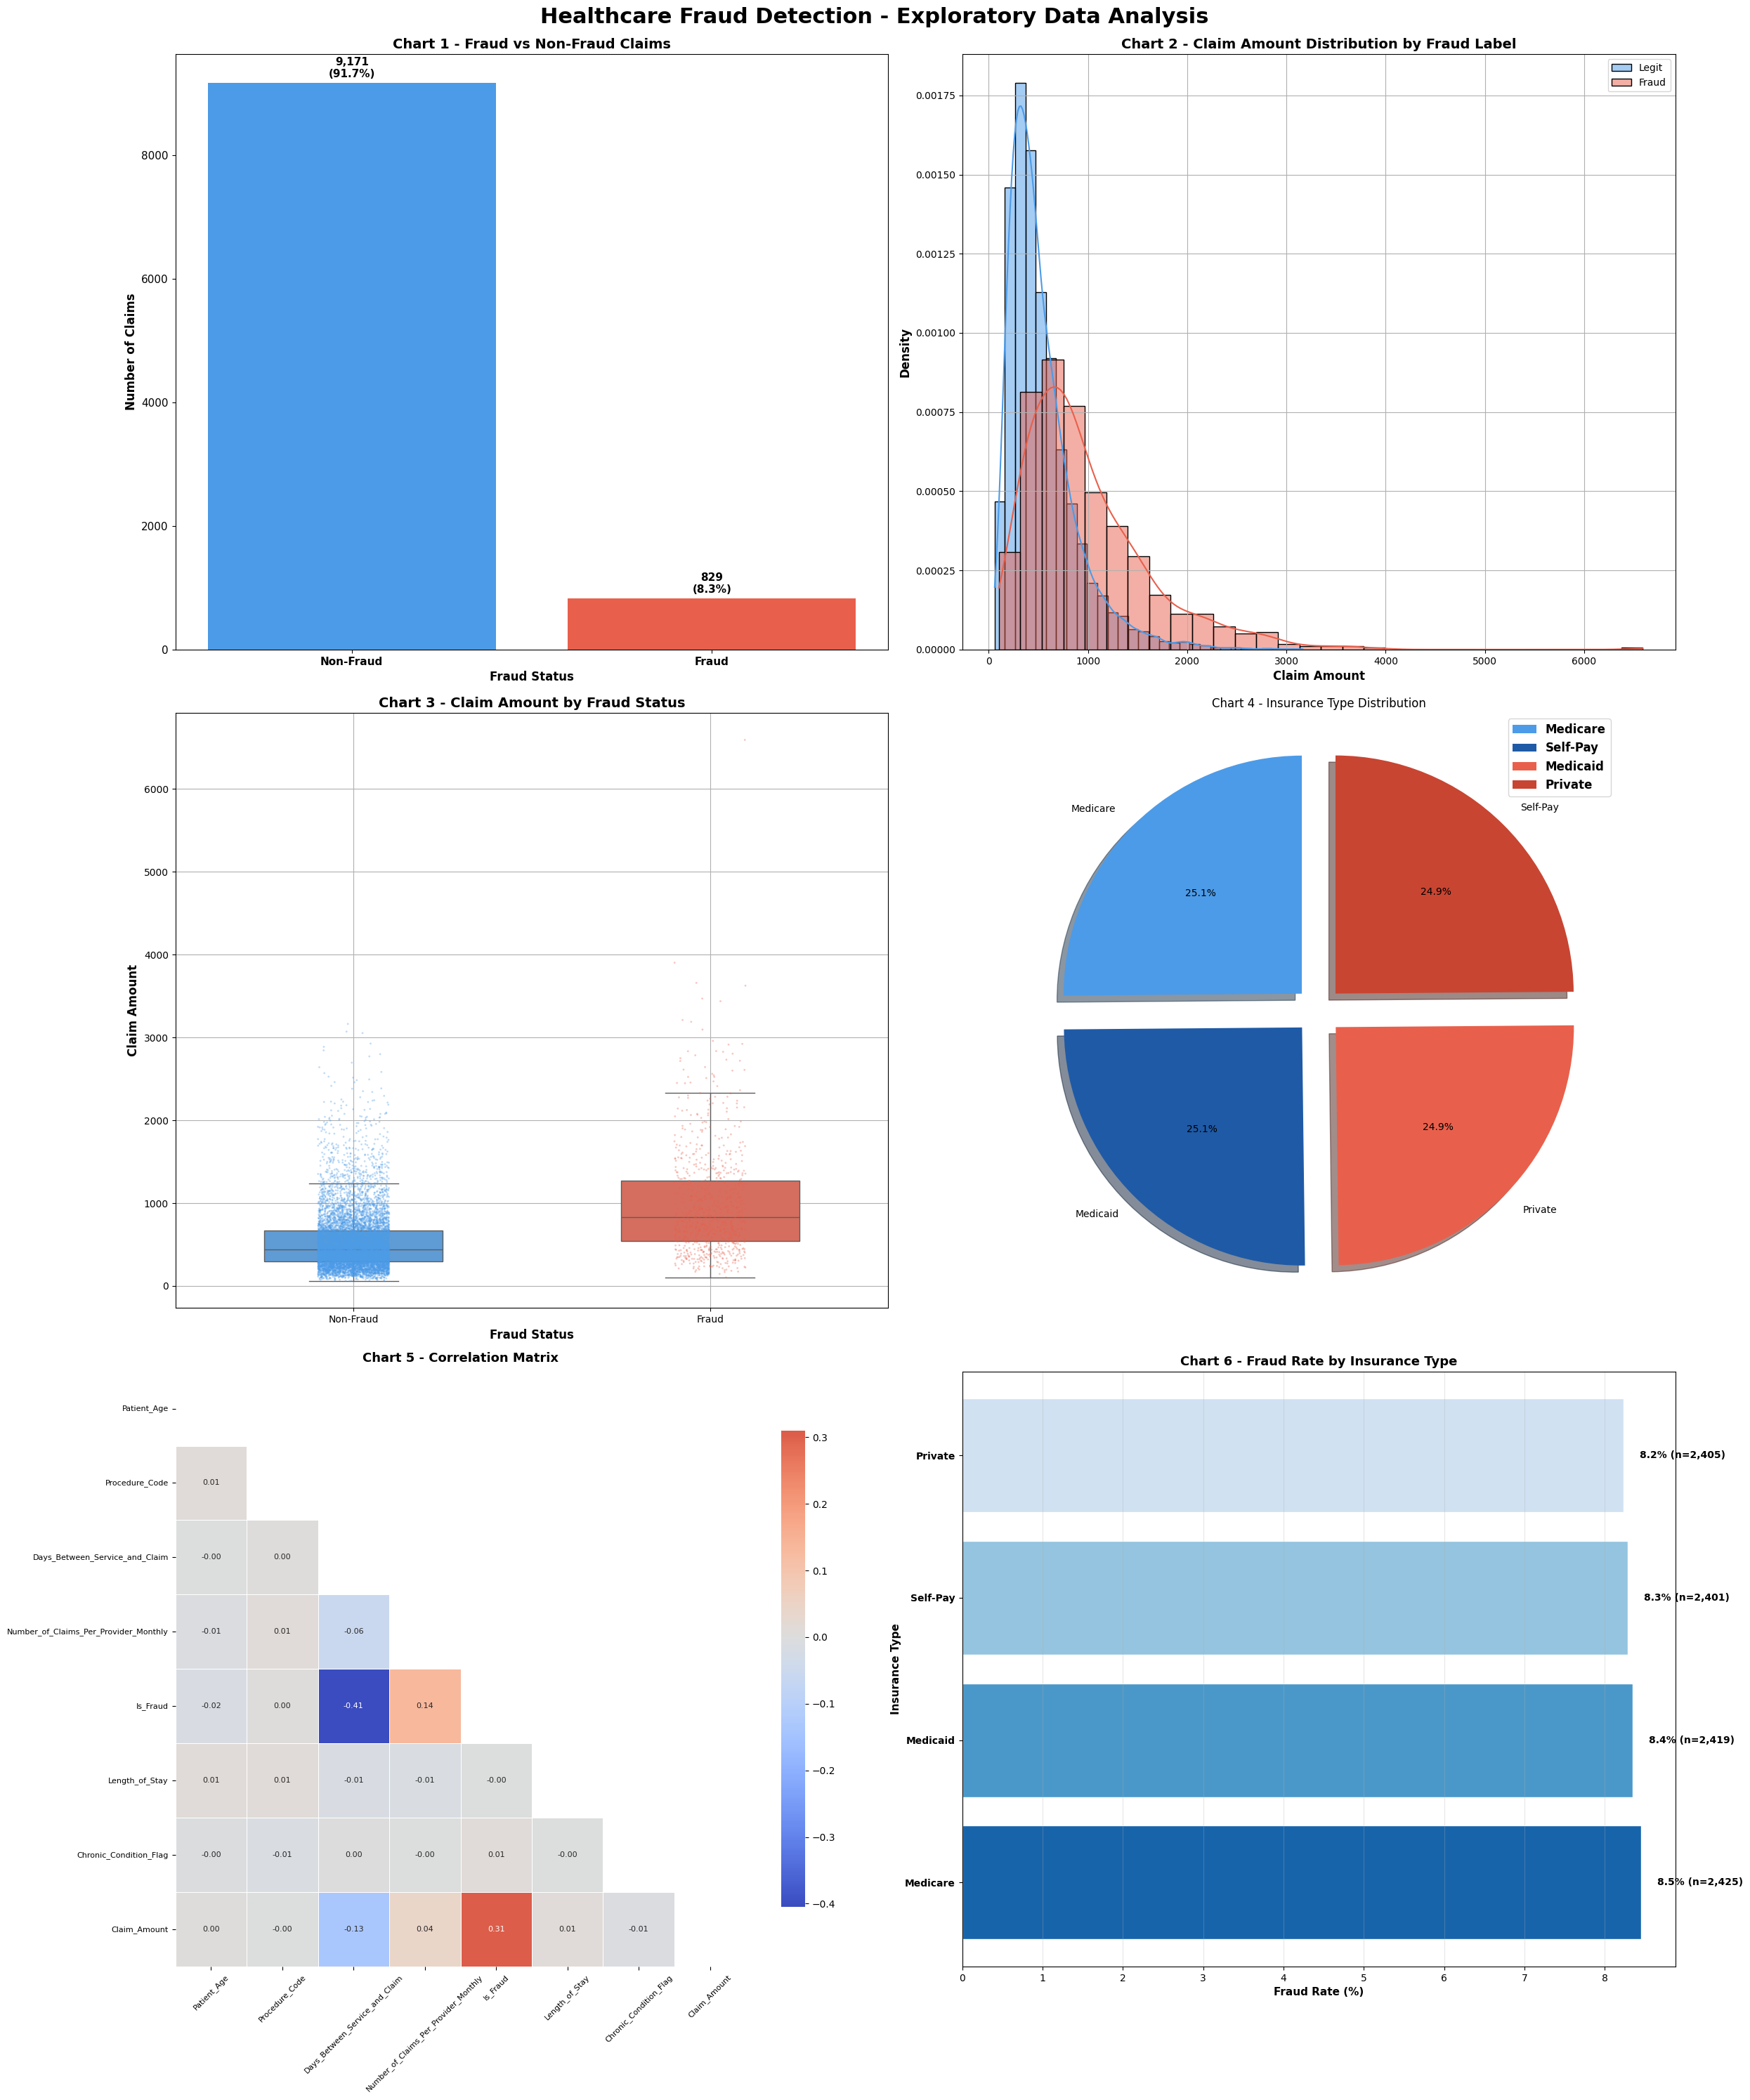

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("healthcare_fraud_detection.csv")

# '#F7F9FC'
# '#4C9BE8'

# Create a figure with four subplots
fig = plt.figure(figsize = (25, 30)) #specify entire figure size
fig.suptitle('Healthcare Fraud Detection - Exploratory Data Analysis',
             fontsize = 22, fontweight = 'bold', y = 0.995)   #Entire Suplot Title


# Subplot 1: Fraud Distribution

plt.subplot(3,2,1)

fraud_counts = df['Is_Fraud'].value_counts().sort_index()
labels = ['Non-Fraud', 'Fraud']


bars = plt.bar(
    labels,
    fraud_counts.values,
    color=['#4C9BE8', '#E8604C']
)

# Add values on top of each bar
total = len(df)

for bar in bars:
    val = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        val + 50,
        f'{int(val):,}\n({val/total*100:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )


plt.title('Chart 1 - Fraud vs Non-Fraud Claims', fontsize = 14, fontweight = 'bold')
plt.xlabel('Fraud Status', fontsize = 12, fontweight = 'bold')
plt.ylabel('Number of Claims', fontsize = 12, fontweight = 'bold')

plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11)


# Subplot 2: Claim Amount Distribution

plt.subplot(3,2,2)

# Legitimate claims
sns.histplot(
    data=df[df['Is_Fraud'] == 0],
    x='Claim_Amount',
    bins=30,
    stat='density',
    kde=True,
    color='#4C9BE8',
    alpha=0.5,
    label='Legit'
)

# Fraud claims
sns.histplot(
    data=df[df['Is_Fraud'] == 1],
    x='Claim_Amount',
    bins=30,
    stat='density',
    kde=True,
    color='#E8604C',
    alpha=0.5,
    label='Fraud'
)

plt.title('Chart 2 - Claim Amount Distribution by Fraud Label', fontsize = 14, fontweight = 'bold')
plt.xlabel('Claim Amount', fontsize=12, fontweight='bold')
plt.ylabel('Density', fontsize=12, fontweight='bold')

plt.legend()
plt.grid(True)


# Subplot 3: Boxplot of Claim Amount by Fraud Status

plt.subplot(3,2,3)

# Create labels
df['Fraud_Label'] = df['Is_Fraud'].map({
    0: 'Non-Fraud',
    1: 'Fraud'
})

# Boxplot
sns.boxplot(
    data=df,
    x='Fraud_Label',
    y='Claim_Amount',
    palette=['#4C9BE8', '#E8604C'],
    width=0.5,
    showfliers=False
)

# Overlay individual observations
sns.stripplot(
    data=df,
    x='Fraud_Label',
    y='Claim_Amount',
    palette=['#4C9BE8', '#E8604C'],
    alpha=0.35,
    jitter=True,
    size=2
)

plt.title('Chart 3 - Claim Amount by Fraud Status', fontsize=14, fontweight='bold')
plt.xlabel('Fraud Status', fontsize=12, fontweight='bold')
plt.ylabel('Claim Amount', fontsize=12, fontweight='bold')

plt.grid(True)

# Subplot 4: Insurance Type

plt.subplot(3,2,4)

insurance = df['Insurance_Type'].value_counts()

plt.pie(
    insurance.values,
    labels=insurance.index,
    autopct='%1.1f%%',
    shadow=True,
    startangle=90,
    explode=(0.1,0.1,0.1,0.1),
    colors=['#4C9BE8', '#1F5AA6', '#E8604C', '#C84532']
)

plt.title('Chart 4 - Insurance Type Distribution')
plt.legend(
    ['Medicare','Self-Pay','Medicaid','Private'],
    loc='upper right',
    prop = {'size': 12, 'weight': 'bold'}
)


# Subplot 5: Correlatiton Matrix
plt.subplot(3,2,5)
num_col = ['Patient_Age', 'Procedure_Code', 'Days_Between_Service_and_Claim',
       'Number_of_Claims_Per_Provider_Monthly', 'Is_Fraud', 'Length_of_Stay',
       'Chronic_Condition_Flag', 'Claim_Amount']
corr = df[num_col].corr()
mask = np.triu(np.ones_like(corr, dtype = bool))
sns.heatmap(corr, mask = mask, annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0, linewidths = 0.5, annot_kws = {'size': 8}, cbar_kws = {'shrink': 0.8})

plt.title('Chart 5 - Correlation Matrix', fontsize = 13, fontweight = 'bold', pad = 10)
plt.tick_params(axis = 'x', rotation = 45, labelsize = 8)
plt.tick_params(axis = 'y', rotation = 0, labelsize = 8)

plt.tight_layout(rect=[0,0,1,0.98])

# Subplot 6 - Fraud Rate by Insurance Type (Horizontal Bar Chart)

plt.subplot(3,2,6)

# Calculate fraud rate and count
ins = df.groupby('Insurance_Type')['Is_Fraud'].agg(['mean', 'count'])
ins = ins.sort_values('mean', ascending=False)

# Create horizontal bar chart
bars = plt.barh(
    ins.index,
    ins['mean'] * 100,
    color=sns.color_palette('Blues_r', len(ins)),
    edgecolor='white'
)

# Add labels to each bar
for bar, (_, row) in zip(bars, ins.iterrows()):
    plt.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{row['mean']*100:.1f}% (n={int(row['count']):,})",
        va='center',
        fontsize=10,
        fontweight='bold'
    )

# Chart formatting
plt.title(
    'Chart 6 - Fraud Rate by Insurance Type',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Fraud Rate (%)',
    fontsize=11,
    fontweight='bold'
)

plt.ylabel(
    'Insurance Type',
    fontsize=11,
    fontweight='bold'
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.savefig('healthcare_fraud_Analysis.png', dpi=150, bbox_inches = 'tight', facecolor = 'white')

# Adjust spacing
plt.tight_layout()

# Display the figure
plt.show()